# Fase 4: Analisis de Features Negativos y Baja Relevancia

**Tesis:** Modelo Predictivo de Resultados - Premier League 2017-2025  
**Objetivo:** Identificar features que perjudican el modelo y medir impacto de eliminarlas  
**Input:** `model_dataset_selected.csv`

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
import time
warnings.filterwarnings('ignore')

from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.inspection import permutation_importance
from sklearn.metrics import f1_score, accuracy_score, roc_auc_score
from sklearn.base import clone

import sys
sys.path.insert(0, '.')
from utils.split_utils import expanding_window_split, print_fold_summary
from utils.evaluation_utils import evaluate_model

sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams['figure.dpi'] = 120
TARGET = 'target_home_win'
print('Librerias cargadas.')

Librerias cargadas.


In [2]:
df = pd.read_csv('Dataset/model_dataset_selected.csv')
X = df.drop(columns=[TARGET, 'season'])
y = df[TARGET]
print(f'Dataset: {df.shape[0]} filas, {X.shape[1]} features')
folds = expanding_window_split(df, min_train_seasons=1)
print_fold_summary(folds, df)

Dataset: 2973 filas, 28 features
RESUMEN DE FOLDS — EXPANDING WINDOW
Total de partidos: 2973
Total de folds: 7

Fold 1:
  Train: ['2017-2018']
         347 partidos (11.7%)
  Test:  2018-2019
         371 partidos (12.5%)

Fold 2:
  Train: ['2017-2018', '2018-2019']
         718 partidos (24.2%)
  Test:  2019-2020
         371 partidos (12.5%)

Fold 3:
  Train: ['2017-2018', '2018-2019', '2019-2020']
         1089 partidos (36.6%)
  Test:  2020-2021
         377 partidos (12.7%)

Fold 4:
  Train: ['2017-2018', '2018-2019', '2019-2020', '2020-2021']
         1466 partidos (49.3%)
  Test:  2021-2022
         377 partidos (12.7%)

Fold 5:
  Train: ['2017-2018', '2018-2019', '2019-2020', '2020-2021', '2021-2022']
         1843 partidos (62.0%)
  Test:  2022-2023
         377 partidos (12.7%)

Fold 6:
  Train: ['2017-2018', '2018-2019', '2019-2020', '2020-2021', '2021-2022', '2022-2023']
         2220 partidos (74.7%)
  Test:  2023-2024
         376 partidos (12.6%)

Fold 7:
  Train: ['2017

---
## 1. Importancia de Features Across Folds

Promediamos la importancia de RF y GB en cada fold para obtener una estimacion mas estable.

In [3]:
rf_importances = []
gb_importances = []

for fold_idx, (train_idx, test_idx, train_s, test_s) in enumerate(folds):
    X_train = X.iloc[train_idx]
    y_train = y.iloc[train_idx]
    
    rf = RandomForestClassifier(n_estimators=400, max_depth=12, min_samples_leaf=4, random_state=42, n_jobs=-1, class_weight='balanced')
    rf.fit(X_train, y_train)
    rf_importances.append(pd.Series(rf.feature_importances_, index=X.columns))
    
    gb = GradientBoostingClassifier(n_estimators=400, learning_rate=0.05, max_depth=4, subsample=0.8, random_state=42)
    gb.fit(X_train, y_train)
    gb_importances.append(pd.Series(gb.feature_importances_, index=X.columns))
    print(f'Fold {fold_idx+1}: {train_s} -> {test_s} OK')

rf_avg = pd.concat(rf_importances, axis=1).mean(axis=1)
gb_avg = pd.concat(gb_importances, axis=1).mean(axis=1)
avg_importance = ((rf_avg + gb_avg) / 2).sort_values(ascending=False)
print('\nImportancias promedio calculadas.')

Fold 1: ['2017-2018'] -> 2018-2019 OK


Fold 2: ['2017-2018', '2018-2019'] -> 2019-2020 OK


Fold 3: ['2017-2018', '2018-2019', '2019-2020'] -> 2020-2021 OK


Fold 4: ['2017-2018', '2018-2019', '2019-2020', '2020-2021'] -> 2021-2022 OK


Fold 5: ['2017-2018', '2018-2019', '2019-2020', '2020-2021', '2021-2022'] -> 2022-2023 OK


Fold 6: ['2017-2018', '2018-2019', '2019-2020', '2020-2021', '2021-2022', '2022-2023'] -> 2023-2024 OK


Fold 7: ['2017-2018', '2018-2019', '2019-2020', '2020-2021', '2021-2022', '2022-2023', '2023-2024'] -> 2024-2025 OK

Importancias promedio calculadas.


---
## 2. Features con Importancia ~0

Consideramos importancia baja si es menor al 0.1% de la importancia total.

Features con importancia < 0.001: 0


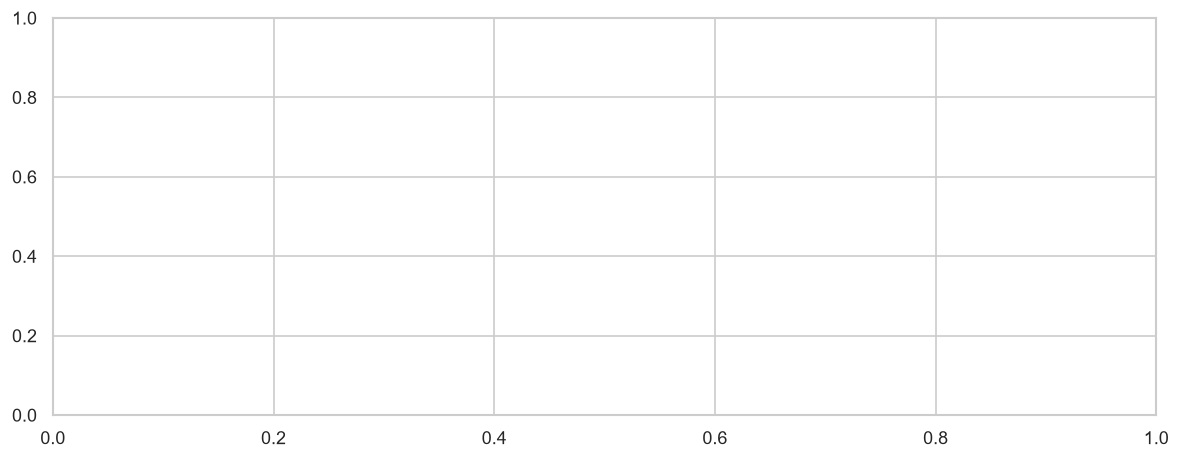

In [4]:
threshold = 0.001
low_importance = avg_importance[avg_importance < threshold].sort_values()

print(f'Features con importancia < {threshold}: {len(low_importance)}')
for feat, imp in low_importance.items():
    print(f'  {imp:.6f}  {feat}')

fig, ax = plt.subplots(figsize=(10, max(4, len(low_importance) * 0.4)))
if len(low_importance) > 0:
    low_importance.plot(kind='barh', color='#e07b71', edgecolor='white', ax=ax)
    ax.axvline(threshold, color='red', linestyle='--', linewidth=1.5)
    ax.set_title(f'Features con Importancia < {threshold}')
    ax.set_xlabel('Importancia promedio')
plt.tight_layout()
plt.savefig('Imagenes/features_negativos/low_importance.png', bbox_inches='tight', dpi=120)
plt.show()

---
## 3. Permutation Importance

Mas robusto que la importancia de arboles. Mide cuanto empeora el modelo al mezclar una feature.

In [5]:
last_fold = folds[-1]
X_train = X.iloc[last_fold[0]]
y_train = y.iloc[last_fold[0]]
X_test = X.iloc[last_fold[1]]
y_test = y.iloc[last_fold[1]]

gb = GradientBoostingClassifier(n_estimators=400, learning_rate=0.05, max_depth=4, subsample=0.8, random_state=42)
gb.fit(X_train, y_train)

print('Calculando Permutation Importance...')
start = time.time()
perm_result = permutation_importance(gb, X_test, y_test, n_repeats=10, random_state=42, scoring='f1', n_jobs=-1)
print(f'Completado en {time.time()-start:.2f}s')

perm_importance = pd.DataFrame({
    'feature': X.columns,
    'importance_mean': perm_result.importances_mean,
    'importance_std': perm_result.importances_std
}).sort_values('importance_mean', ascending=False)

print('\nTop 20 por Permutation Importance:')
for _, row in perm_importance.head(20).iterrows():
    print(f'  {row["importance_mean"]:.4f} +/- {row["importance_std"]:.4f}  {row["feature"]}')

Calculando Permutation Importance...


Completado en 9.00s

Top 20 por Permutation Importance:
  0.1325 +/- 0.0232  odds_home_prob
  0.0111 +/- 0.0100  home_roll_corners
  0.0094 +/- 0.0126  diff_team_int_per90
  0.0090 +/- 0.0093  diff_player_quality
  0.0034 +/- 0.0094  away_roll_shots
  0.0019 +/- 0.0084  diff_gk_cs_pct
  0.0014 +/- 0.0089  market_form_diff
  0.0009 +/- 0.0077  home_season_goals_against
  0.0009 +/- 0.0086  diff_team_discipline_per90
  0.0005 +/- 0.0065  diff_top3_ga_per90
  -0.0001 +/- 0.0076  home_ground_advantage
  -0.0004 +/- 0.0076  diff_team_tkl_per90
  -0.0020 +/- 0.0110  away_season_goals_against
  -0.0020 +/- 0.0030  diff_squad_depth
  -0.0033 +/- 0.0057  h2h_away_goals_avg
  -0.0039 +/- 0.0067  home_roll_away_points
  -0.0046 +/- 0.0049  home_roll_home_points
  -0.0050 +/- 0.0104  diff_squad_age
  -0.0056 +/- 0.0046  streak_clash
  -0.0070 +/- 0.0094  market_uncertainty


Features con permutation importance <= 0.005: 24
  [BAJA] 0.0034  away_roll_shots
  [BAJA] 0.0019  diff_gk_cs_pct
  [BAJA] 0.0014  market_form_diff
  [BAJA] 0.0009  home_season_goals_against
  [BAJA] 0.0009  diff_team_discipline_per90
  [BAJA] 0.0005  diff_top3_ga_per90
  [NEGATIVA] -0.0001  home_ground_advantage
  [NEGATIVA] -0.0004  diff_team_tkl_per90
  [NEGATIVA] -0.0020  away_season_goals_against
  [NEGATIVA] -0.0020  diff_squad_depth
  [NEGATIVA] -0.0033  h2h_away_goals_avg
  [NEGATIVA] -0.0039  home_roll_away_points
  [NEGATIVA] -0.0046  home_roll_home_points
  [NEGATIVA] -0.0050  diff_squad_age
  [NEGATIVA] -0.0056  streak_clash
  [NEGATIVA] -0.0070  market_uncertainty
  [NEGATIVA] -0.0072  h2h_home_goals_avg
  [NEGATIVA] -0.0075  home_roll_goals_conceded
  [NEGATIVA] -0.0084  away_roll_corners
  [NEGATIVA] -0.0088  diff_gk_save_pct
  [NEGATIVA] -0.0092  diff_avg_on_off
  [NEGATIVA] -0.0103  away_roll_goals_conceded
  [NEGATIVA] -0.0162  home_roll_shots
  [NEGATIVA] -0.0166  ho

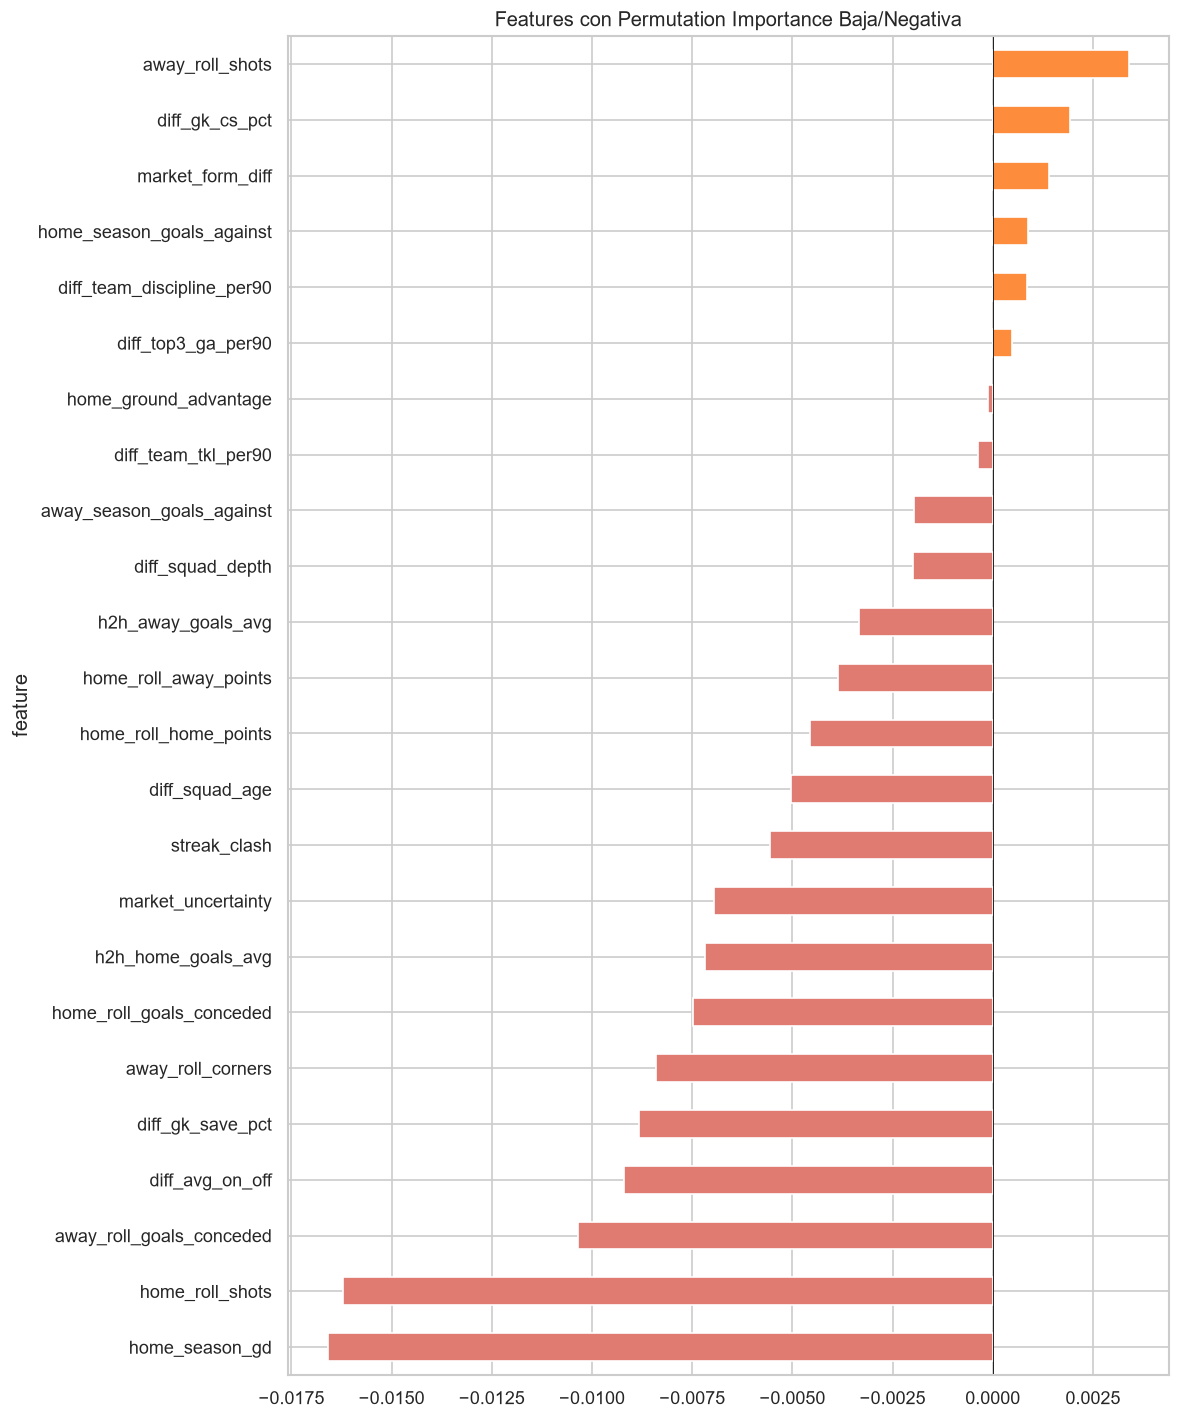

In [6]:
bad_features_perm = perm_importance[perm_importance['importance_mean'] <= 0.005]
print(f'Features con permutation importance <= 0.005: {len(bad_features_perm)}')
for _, row in bad_features_perm.iterrows():
    status = 'NEGATIVA' if row['importance_mean'] < 0 else 'BAJA'
    print(f'  [{status}] {row["importance_mean"]:.4f}  {row["feature"]}')

fig, ax = plt.subplots(figsize=(10, max(4, len(bad_features_perm) * 0.5)))
if len(bad_features_perm) > 0:
    bad_sorted = bad_features_perm.set_index('feature').sort_values('importance_mean')
    colors = ['#e07b71' if v < 0 else '#fd8d3c' for v in bad_sorted['importance_mean']]
    bad_sorted['importance_mean'].plot(kind='barh', color=colors, edgecolor='white', ax=ax)
    ax.axvline(0, color='black', linewidth=0.5)
    ax.set_title('Features con Permutation Importance Baja/Negativa')
plt.tight_layout()
plt.savefig('Imagenes/features_negativos/permutation_bad.png', bbox_inches='tight', dpi=120)
plt.show()

---
## 4. Coeficientes de Regresion Logistica

Los coeficientes muestran la direccion del efecto de cada feature.

In [7]:
scaler = StandardScaler()
X_train_sc = scaler.fit_transform(X.iloc[folds[-1][0]])
y_train = y.iloc[folds[-1][0]]

lr = LogisticRegression(max_iter=1000, C=1.0, random_state=42, class_weight='balanced')
lr.fit(X_train_sc, y_train)

coef_df = pd.DataFrame({
    'feature': X.columns,
    'coefficient': lr.coef_[0],
    'abs_coefficient': np.abs(lr.coef_[0])
}).sort_values('abs_coefficient', ascending=False)

print('Top 15 features por |coeficiente|:')
for _, row in coef_df.head(15).iterrows():
    d = '+' if row['coefficient'] > 0 else '-'
    print(f'  {d}{abs(row["coefficient"]):.4f}  {row["feature"]}')

print(f'\nFeatures con coeficiente negativo: {len(coef_df[coef_df["coefficient"] < 0])}')

Top 15 features por |coeficiente|:
  +0.7594  odds_home_prob
  +0.1719  home_season_goals_against
  +0.1426  home_season_gd
  -0.1270  diff_team_int_per90
  +0.1033  market_form_diff
  +0.0889  away_roll_goals_conceded
  -0.0875  away_season_goals_against
  +0.0803  diff_avg_on_off
  -0.0764  away_roll_corners
  -0.0706  home_roll_goals_conceded
  +0.0620  diff_squad_depth
  +0.0597  streak_clash
  -0.0552  home_roll_home_points
  +0.0542  diff_player_quality
  +0.0511  diff_gk_save_pct

Features con coeficiente negativo: 11


---
## 5. Prueba de Eliminacion

Combinamos los 3 metodos para identificar candidatas a eliminacion, luego medimos impacto.

In [8]:
# Combinar criterios
low_gini = set(avg_importance[avg_importance < 0.001].index)
low_perm = set(perm_importance[perm_importance['importance_mean'] <= 0.005]['feature'])
low_coef = set(coef_df[coef_df['abs_coefficient'] < 0.05]['feature'])

# Candidatas que aparecen en al menos 2 de 3 metodos
from collections import Counter
counter = Counter()
for feat in X.columns:
    votes = 0
    if feat in low_gini: votes += 1
    if feat in low_perm: votes += 1
    if feat in low_coef: votes += 1
    if votes >= 2:
        counter[feat] = votes

features_to_test = sorted(counter.keys(), key=lambda x: counter[x], reverse=True)

print(f'Features candidatas a eliminar (>= 2 metodos): {len(features_to_test)}')
for f in features_to_test:
    print(f'  {counter[f]}/3 metodos: {f}')

Features candidatas a eliminar (>= 2 metodos): 12
  2/3 metodos: home_roll_shots
  2/3 metodos: home_roll_away_points
  2/3 metodos: away_roll_shots
  2/3 metodos: h2h_home_goals_avg
  2/3 metodos: h2h_away_goals_avg
  2/3 metodos: diff_gk_cs_pct
  2/3 metodos: diff_top3_ga_per90
  2/3 metodos: diff_squad_age
  2/3 metodos: diff_team_tkl_per90
  2/3 metodos: diff_team_discipline_per90
  2/3 metodos: home_ground_advantage
  2/3 metodos: market_uncertainty


In [9]:
# Prueba de eliminacion: una por una
results_elimination = []
base_f1 = 0

for fold_idx, (train_idx, test_idx, train_s, test_s) in enumerate(folds[:3]):
    X_tr = X.iloc[train_idx]
    y_tr = y.iloc[train_idx]
    X_te = X.iloc[test_idx]
    y_te = y.iloc[test_idx]
    
    gb_base = GradientBoostingClassifier(n_estimators=400, learning_rate=0.05, max_depth=4, subsample=0.8, random_state=42)
    gb_base.fit(X_tr, y_tr)
    y_pred_base = gb_base.predict(X_te)
    base_f1 += f1_score(y_te, y_pred_base)

base_f1 /= 3
print(f'Baseline F1 (3 folds): {base_f1:.4f}')

# Testear eliminacion de cada feature
for feat in features_to_test:
    X_reduced = X.drop(columns=[feat])
    f1_scores = []
    
    for fold_idx, (train_idx, test_idx, train_s, test_s) in enumerate(folds[:3]):
        X_tr = X_reduced.iloc[train_idx]
        y_tr = y.iloc[train_idx]
        X_te = X_reduced.iloc[test_idx]
        y_te = y.iloc[test_idx]
        
        gb = GradientBoostingClassifier(n_estimators=400, learning_rate=0.05, max_depth=4, subsample=0.8, random_state=42)
        gb.fit(X_tr, y_tr)
        y_pred = gb.predict(X_te)
        f1_scores.append(f1_score(y_te, y_pred))
    
    avg_f1 = np.mean(f1_scores)
    diff = avg_f1 - base_f1
    results_elimination.append({'feature': feat, 'f1_without': avg_f1, 'diff': diff})
    print(f'  Quitar {feat}: F1={avg_f1:.4f} (diff={diff:+.4f})')

Baseline F1 (3 folds): 0.5640


  Quitar home_roll_shots: F1=0.5714 (diff=+0.0073)


  Quitar home_roll_away_points: F1=0.5801 (diff=+0.0160)


  Quitar away_roll_shots: F1=0.5767 (diff=+0.0127)


  Quitar h2h_home_goals_avg: F1=0.5618 (diff=-0.0022)


  Quitar h2h_away_goals_avg: F1=0.5778 (diff=+0.0137)


... (3 outputs left out)

  Quitar diff_team_tkl_per90: F1=0.5739 (diff=+0.0099)


  Quitar diff_team_discipline_per90: F1=0.5650 (diff=+0.0010)


  Quitar home_ground_advantage: F1=0.5787 (diff=+0.0147)


  Quitar market_uncertainty: F1=0.5754 (diff=+0.0114)



IMPACTO DE ELIMINAR FEATURES:
  [MEJORA] home_roll_away_points: +0.0160
  [MEJORA] home_ground_advantage: +0.0147
  [MEJORA] h2h_away_goals_avg: +0.0137
  [MEJORA] away_roll_shots: +0.0127
  [MEJORA] diff_gk_cs_pct: +0.0126
  [MEJORA] diff_squad_age: +0.0121
  [MEJORA] market_uncertainty: +0.0114
  [MEJORA] diff_team_tkl_per90: +0.0099
  [MEJORA] home_roll_shots: +0.0073
  [MEJORA] diff_top3_ga_per90: +0.0056
  [NEUTRO] diff_team_discipline_per90: +0.0010
  [EMPEORA] h2h_home_goals_avg: -0.0022


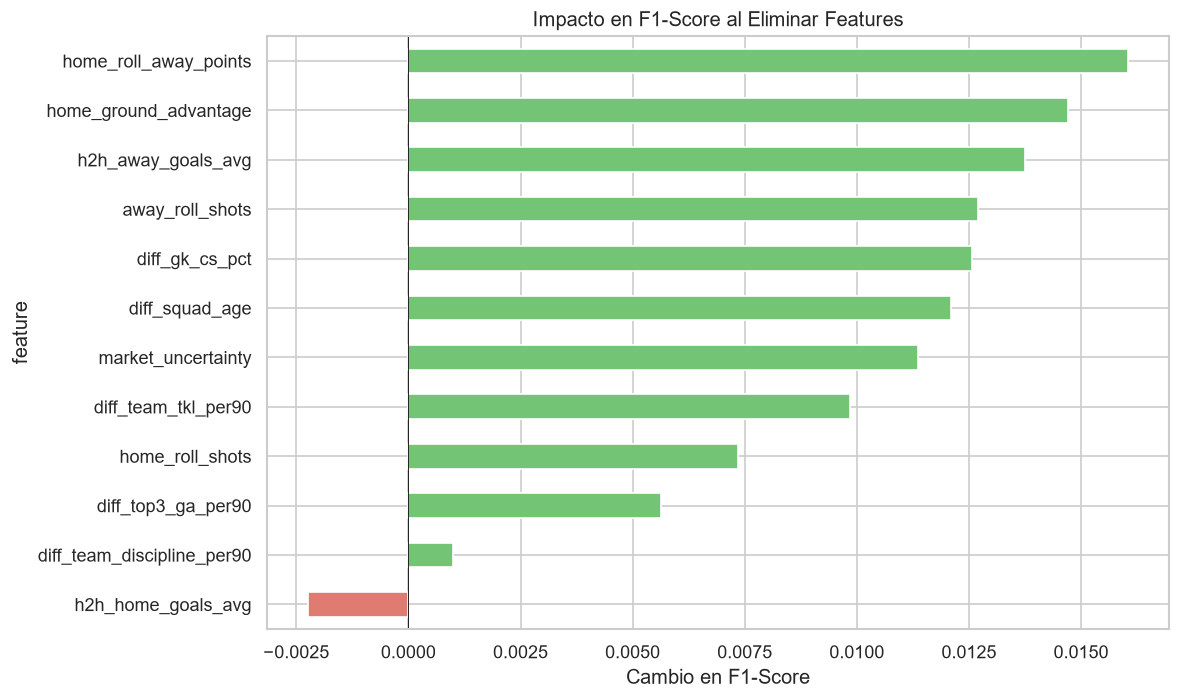

In [10]:
df_elim = pd.DataFrame(results_elimination).sort_values('diff', ascending=False)

print('\nIMPACTO DE ELIMINAR FEATURES:')
print('='*60)
for _, row in df_elim.iterrows():
    status = 'MEJORA' if row['diff'] > 0.001 else ('EMPEORA' if row['diff'] < -0.001 else 'NEUTRO')
    print(f'  [{status}] {row["feature"]}: {row["diff"]:+.4f}')

fig, ax = plt.subplots(figsize=(10, max(4, len(df_elim) * 0.5)))
df_plot = df_elim.set_index('feature').sort_values('diff')
colors = ['#74c476' if v > 0 else '#e07b71' for v in df_plot['diff']]
df_plot['diff'].plot(kind='barh', color=colors, edgecolor='white', ax=ax)
ax.axvline(0, color='black', linewidth=0.5)
ax.set_title('Impacto en F1-Score al Eliminar Features')
ax.set_xlabel('Cambio en F1-Score')
plt.tight_layout()
plt.savefig('Imagenes/features_negativos/elimination_impact.png', bbox_inches='tight', dpi=120)
plt.show()

---
## 6. Dataset Final Optimizado

Eliminamos las features que mejoran o no afectan el rendimiento.

In [11]:
# Eliminar features que mejoran o son neutras
features_safe_to_drop = df_elim[df_elim['diff'] >= -0.001]['feature'].tolist()

print(f'Features a eliminar: {len(features_safe_to_drop)}')
for f in features_safe_to_drop:
    diff = df_elim[df_elim['feature'] == f]['diff'].values[0]
    print(f'  {f}: {diff:+.4f}')

# Guardar dataset final
if len(features_safe_to_drop) > 0:
    df_final = df.drop(columns=[c for c in features_safe_to_drop if c in df.columns])
else:
    df_final = df.copy()

df_final.to_csv('Dataset/model_dataset_final.csv', index=False)
print(f'\nDataset final guardado: {df_final.shape}')
print(f'Features finales: {df_final.shape[1] - 1}')

Features a eliminar: 11
  home_roll_away_points: +0.0160
  home_ground_advantage: +0.0147
  h2h_away_goals_avg: +0.0137
  away_roll_shots: +0.0127
  diff_gk_cs_pct: +0.0126
  diff_squad_age: +0.0121
  market_uncertainty: +0.0114
  diff_team_tkl_per90: +0.0099
  home_roll_shots: +0.0073
  diff_top3_ga_per90: +0.0056
  diff_team_discipline_per90: +0.0010

Dataset final guardado: (2973, 19)
Features finales: 18


In [12]:
print('='*70)
print('RESUMEN - FEATURES NEGATIVOS')
print('='*70)
print(f'Features analizadas: {X.shape[1]}')
print(f'Candidatas a eliminar: {len(features_to_test)}')
print(f'Eliminadas (seguras): {len(features_safe_to_drop)}')
print(f'Features finales: {df_final.shape[1] - 1}')
print(f'Baseline F1: {base_f1:.4f}')
if len(features_safe_to_drop) > 0:
    best_diff = df_elim[df_elim["feature"].isin(features_safe_to_drop)]["diff"].max()
    print(f'Mejora maxima por eliminacion: {best_diff:+.4f}')
print('\nGuardado: Dataset/model_dataset_final.csv')
print('='*70)

RESUMEN - FEATURES NEGATIVOS
Features analizadas: 28
Candidatas a eliminar: 12
Eliminadas (seguras): 11
Features finales: 18
Baseline F1: 0.5640
Mejora maxima por eliminacion: +0.0160

Guardado: Dataset/model_dataset_final.csv
